Companion notebook to `04_fraud_project.ipynb` (Fraud Detection, STEG).

In [23]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, fbeta_score, recall_score, precision_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from scipy.stats import loguniform, randint, uniform, rankdata
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
# pip install lightgbm catboost imbalanced-learn   (if a library is missing)

Same paths as the team notebook. If `data/split/holdout_ids.csv` exists, we use it, so the split is **guaranteed** to be the team split.

In [30]:
client_train = pd.read_csv("data/train/client_train.csv")
invoice_train = pd.read_csv("data/train/invoice_train.csv", low_memory=False)

ids_path = Path("data/split/holdout_ids.csv")
if ids_path.exists():
    holdout_ids = set(pd.read_csv(ids_path)["client_id"])
    holdout_clients = client_train[client_train["client_id"].isin(holdout_ids)]
    train_clients = client_train[~client_train["client_id"].isin(holdout_ids)]
    print("split loaded from", ids_path)
else:
    train_clients, holdout_clients = train_test_split(
        client_train, test_size=0.2, stratify=client_train["target"], random_state=SEED)
    print("split recreated (same settings as Stage 2)")

train_invoices = invoice_train[invoice_train["client_id"].isin(train_clients["client_id"])]

# delete bills with invalid counter_statue
valid_values = ["0", "1", "2", "3", "4", "5"]
def clean(invoices):
    """Luca's cleaning (PR #19): delete bills with invalid counter_statue."""
    return invoices[invoices["counter_statue"].astype(str).isin(valid_values)]

train_invoices = train_invoices[train_invoices["counter_statue"].astype(str).isin(valid_values)]

print("train clients :", train_clients.shape, f"fraud rate {train_clients['target'].mean():.2%}")
print("train invoices:", train_invoices.shape)

split loaded from data\split\holdout_ids.csv
train clients : (108394, 6) fraud rate 5.58%
train invoices: (3590875, 16)


In [3]:
LEVELS = ["consommation_level_1", "consommation_level_2", "consommation_level_3", "consommation_level_4"]


def most_common(invoices, col):
    """Most common value of col per client; on a tie the smaller value wins (same as .mode())."""
    counts = invoices.groupby(["client_id", col]).size().rename("n").reset_index()
    top = counts.sort_values(["n", col], ascending=[False, True]).drop_duplicates("client_id")
    return top.set_index("client_id")[col]


def build_features(clients, invoices):
    inv = invoices.copy()
    inv["invoice_date"] = pd.to_datetime(inv["invoice_date"])
    inv["counter_statue"] = inv["counter_statue"].astype(str)
    inv["total"] = inv[LEVELS].sum(axis=1)
    inv["zero"] = inv["total"] == 0
    inv["mismatch"] = inv["total"] != inv["new_index"] - inv["old_index"]
    inv["months_error"] = inv["months_number"] > 240
    months = inv["months_number"].where((inv["months_number"] > 0) & ~inv["months_error"])
    inv["total_per_month"] = inv["total"] / months

    agg = inv.groupby("client_id").agg(
        n_invoices=("total", "size"),
        n_counters=("counter_number", "nunique"),
        level_1_mean=("consommation_level_1", "mean"),
        level_2_mean=("consommation_level_2", "mean"),
        level_3_mean=("consommation_level_3", "mean"),
        level_4_mean=("consommation_level_4", "mean"),
        total_mean=("total", "mean"),
        total_std=("total", "std"),
        zero_share=("zero", "mean"),
        total_per_month_mean=("total_per_month", "mean"),
        months_error=("months_error", "max"),
        mismatch_any=("mismatch", "max"),
        first_invoice=("invoice_date", "min"),
        last_invoice=("invoice_date", "max"),
    )
    agg["history_years"] = (agg.pop("last_invoice") - agg.pop("first_invoice")).dt.days / 365.25

    cl = clients.set_index("client_id")
    feats = cl[["region"]].copy()
    feats["catg_51"] = cl["client_catg"] == 51
    feats = feats.join(agg)
    feats["tarif_not_11"] = most_common(inv, "tarif_type") != 11
    statue = most_common(inv, "counter_statue")
    feats["statue_1"] = statue == "1"
    feats["statue_other"] = ~statue.isin(["0", "1"])

    bool_cols = feats.select_dtypes("bool").columns
    feats[bool_cols] = feats[bool_cols].astype(int)
    if "target" in cl:
        feats["target"] = cl["target"].astype(int)
    return feats


train_features = build_features(train_clients, train_invoices)

X_train = train_features.drop(columns=["target", "region"])   # the 17 baseline features
y_train = train_features["target"]

# Clients who lost ALL their bills in Luca's cleaning get NaN in the flags (True/False/NaN -> dtype object).
# Logistic Regression accepts that, LightGBM does not -> convert every feature to float.
print("object columns before the fix:", list(X_train.columns[X_train.dtypes == "object"]))
X_train = X_train.astype(float)
print("X_train:", X_train.shape, "| fraud rate:", f"{y_train.mean():.2%}")
print(list(X_train.columns))

object columns before the fix: ['months_error', 'mismatch_any', 'tarif_not_11', 'statue_1', 'statue_other']
X_train: (108394, 17) | fraud rate: 5.58%
['catg_51', 'n_invoices', 'n_counters', 'level_1_mean', 'level_2_mean', 'level_3_mean', 'level_4_mean', 'total_mean', 'total_std', 'zero_share', 'total_per_month_mean', 'months_error', 'mismatch_any', 'history_years', 'tarif_not_11', 'statue_1', 'statue_other']


# Stage 5: Model Exploration & CV — 5 models vs. the Logistic Regression baseline


**Logistic Regression (CV AUC 0.788)** with exactly the same setup as Stage 4, so the scores are directly comparable:

| Model | Family | Idea in one sentence |
| --- | --- | --- |
| **LightGBM** | boosting | trees built one after another, each one fixes the mistakes of the previous ones – fast |


**Same rules as the team notebook:**
- same 80/20 split by client (`stratify=target`, `random_state=42`), **holdout stays untouched** until Stage 7,
- Same cleaning (invalid `counter_statue` bills deleted) and the same `build_features` → same 17 baseline features,
- same `StratifiedKFold(5, shuffle=True, random_state=42)` on the train part only,
- metrics: **ROC-AUC** (mean ± spread) + **Recall / Precision / F2** for the business view.

**Rule to "beat" the baseline (ADR-006):** the AUC gain must be larger than the CV spread.

Settings are **reasonable defaults, not tuned yet**.

- **Imbalance (5.6 % fraud):** LightGBM gives fraud cases more weight.
- **Missing values** (`total_std` for clients with 1 bill): LightGBM handles NaN themselves; the scikit-learn models get a median imputer **inside the pipeline**, so it is fitted on the training folds only.
- **No scaling / `log1p` for trees:** trees only look at the order of the values.

In [8]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
median = lambda: SimpleImputer(strategy="median")

models = {
    "Logistic Regression (baseline)": make_pipeline(
        median(), FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000)),

    "LightGBM": LGBMClassifier(
        n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        scale_pos_weight=pos_weight, random_state=SEED, verbose=-1, n_jobs=-1),
}
print(f"scale_pos_weight = {pos_weight:.1f}")

scale_pos_weight = 16.9


## Same CV as Stage 4

For the model we collect the AUC of each fold **and** the out-of-fold (OOF) probabilities: every client gets a score from the model that did **not** see them in training. The OOF scores are used for the ROC curves and the business metrics.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def run_cv(model, X, y):
    oof = np.zeros(len(X))
    fold_auc = []
    start = time.time()
    for fit_idx, val_idx in cv.split(X, y):
        m = clone(model)
        m.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        oof[val_idx] = m.predict_proba(X.iloc[val_idx])[:, 1]
        fold_auc.append(roc_auc_score(y.iloc[val_idx], oof[val_idx]))
    return np.array(fold_auc), oof, time.time() - start


cv_results, oof_scores = {}, {}
for name, model in models.items():
    aucs, oof, secs = run_cv(model, X_train, y_train)
    cv_results[name], oof_scores[name] = aucs, oof
    print(f"{name:32s} AUC {aucs.mean():.3f} ± {aucs.std():.3f}   ({secs:5.0f} s)")

Logistic Regression (baseline)   AUC 0.788 ± 0.008   (    5 s)
LightGBM                         AUC 0.808 ± 0.009   (   22 s)


## Business metrics: "STEG inspects the top 10 % of clients"

AUC has no threshold. STEG needs a yes/no list, so we use a fixed rule: **the 10 % most suspicious clients are inspected** (≈ 2× the fraud rate). The same rule for every model → fair comparison.

- **Recall** = share of all fraud clients that end up on the list.
- **Precision** = share of the inspected clients who really cheat (hit rate of a visit).
- **F2** = combines both, counts recall double (ADR-004).

In [10]:
INSPECT_SHARE = 0.10


def business_metrics(y, scores, share=INSPECT_SHARE):
    threshold = np.quantile(scores, 1 - share)
    flagged = (scores >= threshold).astype(int)
    return recall_score(y, flagged), precision_score(y, flagged), fbeta_score(y, flagged, beta=2)


base_name = "Logistic Regression (baseline)"
base_auc = cv_results[base_name]

rows = []
for name, aucs in cv_results.items():
    rec, prec, f2 = business_metrics(y_train, oof_scores[name])
    gain = aucs.mean() - base_auc.mean()
    spread = max(aucs.std(), base_auc.std())
    rows.append({"model": name, "auc_mean": aucs.mean(), "auc_std": aucs.std(),
                 "gain_vs_logreg": gain,
                 "beats_baseline": "—" if name == base_name else ("yes" if gain > spread else "no"),
                 f"recall@{INSPECT_SHARE:.0%}": rec, f"precision@{INSPECT_SHARE:.0%}": prec,
                 f"F2@{INSPECT_SHARE:.0%}": f2})

results = pd.DataFrame(rows).sort_values("auc_mean", ascending=False).reset_index(drop=True)
results.round(3)

,model,auc_mean,auc_std,gain_vs_logreg,beats_baseline,recall@10%,precision@10%,F2@10%
0,LightGBM,0.808,0.009,0.02,yes,0.415,0.232,0.358
1,Logistic Regression (baseline),0.788,0.008,0.00,—,0.356,0.199,0.307


## Feature importance of the best model

Which features does the best tree model use most? 

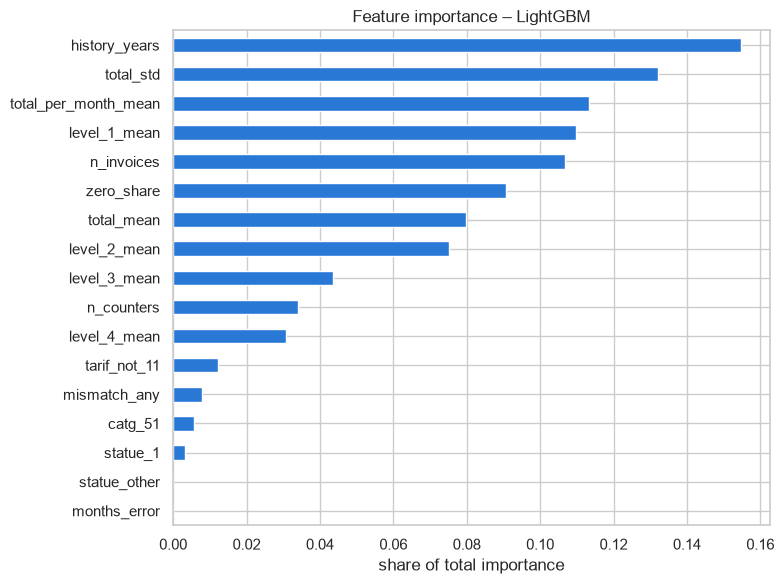

In [11]:
best_name = results.loc[results["model"] != base_name, "model"].iloc[0]
best_model = clone(models[best_name]).fit(X_train, y_train)
est = best_model[-1] if hasattr(best_model, "steps") else best_model

if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=X_train.columns)
elif hasattr(est, "get_feature_importance"):
    imp = pd.Series(est.get_feature_importance(), index=X_train.columns)
imp = (imp / imp.sum()).sort_values()

imp.plot.barh(figsize=(8, 6), color="#2a78d6", title=f"Feature importance – {best_name}")
plt.xlabel("share of total importance"); plt.tight_layout(); plt.show()

## Adding `region` and `disrict` (ADR-008)

The team decided to use `disrict` (vote 3:1); the baseline ran without location. Here we test the best model with `region` and `disrict` added, to see what they really add.
Trees can use the codes directly (no one-hot needed).

In [12]:
X_loc = X_train.join(train_clients.set_index("client_id")[["disrict"]]).assign(region=train_features["region"]).astype(float)

loc_aucs, _, _ = run_cv(models[best_name], X_loc, y_train)
best_aucs = cv_results[best_name]
print(f"{best_name} – 17 features        : {best_aucs.mean():.3f} ± {best_aucs.std():.3f}")
print(f"{best_name} – + region + disrict : {loc_aucs.mean():.3f} ± {loc_aucs.std():.3f}")
print(f"gain from location: {loc_aucs.mean() - best_aucs.mean():+.3f}")

LightGBM – 17 features        : 0.808 ± 0.009
LightGBM – + region + disrict : 0.829 ± 0.005
gain from location: +0.021


## New feature groups

All groups are **fixed rules**: each value uses only the client's own bills or client row → they can be built before the CV without leakage (Stage 3, table 3.1).

| Group | Features | Idea (who) |
| --- | --- | --- |
| `location` | `disrict`, `region` | +0.021 in 05; ADR-008 |
| `variability` | `total_cv`, `total_range_rel`, `total_median`, `total_min`, `level_1_share`, `high_level_share` | Hadi: range ÷ mean, so a bakery and a flat are comparable; Mohamed: inconsistency between bills |
| `trend` | `trend_ratio` (2nd half ÷ 1st half of the bills), `trend_slope`, `last_year_ratio` | a manipulated meter shows a **drop** in consumption |
| `seasonal` | `summer_winter_ratio` | Hadi's seasonal idea, client level (the district comparison is Hadi's feature) |
| `timing` | `gap_mean`, `gap_std`, `gap_max`, `invoices_per_year` | irregular billing / missing readings |
| `elec_gaz` | `n_elec`, `n_gaz`, `elec_mean`, `gaz_mean`, `has_gaz` | Karl's question: separate electricity and gas |
| `meter_codes` | `counter_code_mode`, `n_counter_codes`, `tarif_mode`, `n_tarifs` | `counter_code` was planned for "later" (Stage 2) |
| `index_errors` | `neg_index_share`, `mismatch_share`, `mismatch_count` | readings that go backwards / don't add up |
| `client_age` | `years_as_client`, `bill_before_creation`, `client_catg` | Luca: newer clients cheat less; Hadi: bill before creation flag |

> ⚠️ `trend` and `last_year_ratio` use the **end** of the history – check them for leakage in Stage 6 (was the meter changed *after* the fraud was found? see Stage 2.2).

In [14]:
# float: clients that lost all bills in the cleaning have NaN flags (dtype object) -> LightGBM error
X_base = train_features.drop(columns=["target", "region"]).astype(float)

def extra_features(clients, invoices):
    """Returns {group name: DataFrame indexed by client_id}. Fixed rules only (no fit)."""
    cl = clients.set_index("client_id")
    inv = invoices[["client_id", "invoice_date", "counter_type", "counter_code", "tarif_type",
                    "old_index", "new_index"] + LEVELS].copy()
    inv["invoice_date"] = pd.to_datetime(inv["invoice_date"])
    inv["total"] = inv[LEVELS].sum(axis=1)
    inv = inv.sort_values(["client_id", "invoice_date"]).reset_index(drop=True)
    g = inv.groupby("client_id")
    groups = {}

    groups["location"] = cl[["disrict", "region"]]

    s = g["total"].agg(["mean", "std", "min", "max", "median", "sum"])
    groups["variability"] = pd.DataFrame({
        "total_cv": s["std"] / (s["mean"] + 1),
        "total_range_rel": (s["max"] - s["min"]) / (s["mean"] + 1),
        "total_median": s["median"],
        "total_min": s["min"],
        "level_1_share": g["consommation_level_1"].sum() / (s["sum"] + 1),
        "high_level_share": (g["consommation_level_3"].sum() + g["consommation_level_4"].sum()) / (s["sum"] + 1),
    })

    # trend: 2nd half vs 1st half of the bills, slope over time, last 12 months vs all
    pos, n = g.cumcount(), g["total"].transform("size")
    late = pos >= n / 2
    first_half = inv[~late].groupby("client_id")["total"].mean()
    second_half = inv[late].groupby("client_id")["total"].mean()
    inv["_t"] = (inv["invoice_date"] - g["invoice_date"].transform("min")).dt.days / 365.25
    inv["_ty"], inv["_tt"] = inv["_t"] * inv["total"], inv["_t"] ** 2
    m = inv.groupby("client_id")[["_t", "total", "_ty", "_tt"]].mean()
    var_t = (m["_tt"] - m["_t"] ** 2).where(lambda v: v > 1e-9)
    slope = (m["_ty"] - m["_t"] * m["total"]) / var_t
    last_year = inv["invoice_date"] >= g["invoice_date"].transform("max") - pd.Timedelta(days=365)
    last_year_mean = inv[last_year].groupby("client_id")["total"].mean()
    groups["trend"] = pd.DataFrame({
        "trend_ratio": (second_half + 1) / (first_half + 1),
        "trend_slope": slope / (s["mean"] + 1),
        "last_year_ratio": (last_year_mean + 1) / (s["mean"] + 1),
    })

    month = inv["invoice_date"].dt.month
    summer = inv[month.isin([6, 7, 8])].groupby("client_id")["total"].mean()
    winter = inv[month.isin([12, 1, 2])].groupby("client_id")["total"].mean()
    groups["seasonal"] = pd.DataFrame({"summer_winter_ratio": (summer + 1) / (winter + 1)})

    inv["_gap"] = g["invoice_date"].diff().dt.days
    gaps = inv.groupby("client_id")["_gap"].agg(gap_mean="mean", gap_std="std", gap_max="max")
    years = (g["invoice_date"].max() - g["invoice_date"].min()).dt.days / 365.25
    gaps["invoices_per_year"] = g.size() / (years + 0.25)
    groups["timing"] = gaps

    ctype = inv["counter_type"].astype(str).str.upper()
    eg = inv.assign(ctype=ctype).groupby(["client_id", "ctype"])["total"].agg(["mean", "size"]).unstack()
    col = lambda stat, t: eg[(stat, t)] if (stat, t) in eg.columns else pd.Series(np.nan, index=eg.index)
    groups["elec_gaz"] = pd.DataFrame({
        "n_elec": col("size", "ELEC").fillna(0), "n_gaz": col("size", "GAZ").fillna(0),
        "elec_mean": col("mean", "ELEC"), "gaz_mean": col("mean", "GAZ"),
        "has_gaz": col("size", "GAZ").notna().astype(int)})

    groups["meter_codes"] = pd.DataFrame({
        "counter_code_mode": most_common(inv, "counter_code"),
        "n_counter_codes": g["counter_code"].nunique(),
        "tarif_mode": most_common(inv, "tarif_type"),
        "n_tarifs": g["tarif_type"].nunique()})

    diff = inv["new_index"] - inv["old_index"]
    inv["_neg"], inv["_mis"] = diff < 0, inv["total"] != diff
    idx = inv.groupby("client_id")[["_neg", "_mis"]].agg(["mean", "sum"])
    groups["index_errors"] = pd.DataFrame({
        "neg_index_share": idx[("_neg", "mean")], "mismatch_share": idx[("_mis", "mean")],
        "mismatch_count": idx[("_mis", "sum")]})

    created = pd.to_datetime(cl["creation_date"], dayfirst=True, errors="coerce")
    groups["client_age"] = pd.DataFrame({
        "years_as_client": (pd.Timestamp("2020-01-01") - created).dt.days / 365.25,
        "bill_before_creation": (g["invoice_date"].min().reindex(cl.index) < created).astype(int),
        "client_catg": cl["client_catg"]})

    return {k: v.reindex(cl.index).astype(float) for k, v in groups.items()}


t0 = time.time()
groups = extra_features(train_clients, train_invoices)
print(f"built in {time.time() - t0:.0f} s")
for k, v in groups.items():
    print(f"{k:13s} {v.shape[1]} features, NaN share {v.isna().mean().mean():.1%}")


def make_X(group_names, base=X_base, groups=groups):
    return base.join([groups[g] for g in group_names]).astype(float)

built in 17 s
location      2 features, NaN share 0.0%
variability   6 features, NaN share 0.5%
trend         3 features, NaN share 2.3%
seasonal      1 features, NaN share 25.2%
timing        4 features, NaN share 3.3%
elec_gaz      5 features, NaN share 10.9%
meter_codes   4 features, NaN share 0.0%
index_errors  3 features, NaN share 0.0%
client_age    3 features, NaN share 0.0%


## CV helpers (same CV as Stage 4/5)

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X_base, y_train))


def run_cv(model, X, y=y_train):
    oof, aucs, start = np.zeros(len(X)), [], time.time()
    for fit_idx, val_idx in FOLDS:
        m = clone(model).fit(X.iloc[fit_idx], y.iloc[fit_idx])
        oof[val_idx] = m.predict_proba(X.iloc[val_idx])[:, 1]
        aucs.append(roc_auc_score(y.iloc[val_idx], oof[val_idx]))
    return np.array(aucs), oof, time.time() - start


def fold_aucs(oof, y=y_train):
    return np.array([roc_auc_score(y.iloc[v], oof[v]) for _, v in FOLDS])


lgbm = LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      random_state=SEED, verbose=-1, n_jobs=-1)

## Which feature groups help? (one group at a time)

**Reference:** LightGBM with base 17 + `location`. Every other group is added **alone**. A group is **kept** if its gain is larger than the CV spread of the reference.

> Note: this choice is made with the same CV folds, so the CV score of the final set is slightly optimistic. The untouched holdout (Stage 7) gives the honest number.

In [16]:
ref_groups = ["location"]
ref_auc, _, _ = run_cv(lgbm, make_X(ref_groups))
print(f"reference (base + location): {ref_auc.mean():.4f} ± {ref_auc.std():.4f}\n")

rows = []
for name in [g for g in groups if g not in ref_groups]:
    aucs, _, secs = run_cv(lgbm, make_X(ref_groups + [name]))
    gain = aucs.mean() - ref_auc.mean()
    rows.append({"group": name, "n_features": groups[name].shape[1], "auc_mean": aucs.mean(),
                 "auc_std": aucs.std(), "gain": gain, "keep": gain > ref_auc.std()})
    print(f"+ {name:13s} {aucs.mean():.4f} ± {aucs.std():.4f}   gain {gain:+.4f}   ({secs:.0f} s)")

ablation = pd.DataFrame(rows).sort_values("gain", ascending=False).reset_index(drop=True)
ablation.round(4)

reference (base + location): 0.8302 ± 0.0061

+ variability   0.8308 ± 0.0055   gain +0.0006   (22 s)
+ trend         0.8307 ± 0.0053   gain +0.0005   (28 s)
+ seasonal      0.8296 ± 0.0053   gain -0.0006   (22 s)
+ timing        0.8350 ± 0.0065   gain +0.0048   (40 s)
+ elec_gaz      0.8369 ± 0.0050   gain +0.0067   (35 s)
+ meter_codes   0.8588 ± 0.0057   gain +0.0286   (16 s)
+ index_errors  0.8303 ± 0.0054   gain +0.0001   (41 s)
+ client_age    0.8374 ± 0.0051   gain +0.0072   (28 s)


,group,n_features,auc_mean,auc_std,gain,keep
0,meter_codes,4,0.8588,0.0057,0.0286,True
1,client_age,3,0.8374,0.0051,0.0072,True
2,elec_gaz,5,0.8369,0.0050,0.0067,True
3,timing,4,0.8350,0.0065,0.0048,False
4,variability,6,0.8308,0.0055,0.0006,False
5,trend,3,0.8307,0.0053,0.0005,False
6,index_errors,3,0.8303,0.0054,0.0001,False
7,seasonal,1,0.8296,0.0053,-0.0006,False


In [17]:
kept = ablation.loc[ablation["keep"], "group"].tolist()
candidates = {
    "base + location": ref_groups,
    "base + location + kept groups": ref_groups + kept,
    "base + location + all groups": list(groups),
}
set_results = {}
for label, gl in candidates.items():
    aucs, _, _ = run_cv(lgbm, make_X(gl))
    set_results[label] = aucs
    print(f"{label:32s} {make_X(gl).shape[1]:3d} features   AUC {aucs.mean():.4f} ± {aucs.std():.4f}")

best_set = max(set_results, key=lambda k: set_results[k].mean())
FINAL_GROUPS = candidates[best_set]
X_final = make_X(FINAL_GROUPS)
print(f"\n-> final feature set: {best_set} ({X_final.shape[1]} features), groups: {FINAL_GROUPS}")

base + location                   19 features   AUC 0.8302 ± 0.0061
base + location + kept groups     31 features   AUC 0.8665 ± 0.0049
base + location + all groups      48 features   AUC 0.8662 ± 0.0059

-> final feature set: base + location + kept groups (31 features), groups: ['location', 'meter_codes', 'client_age', 'elec_gaz']


### Decision: feature set

*Fill in after running:* which groups were kept, and the AUC of the final set.
Report the added features to the team (ADR-007).

## Models on the final feature set

The Logistic Regression stays on its 17 baseline features – it is the fixed number to beat (0.788).

In [18]:
models = {
    "LightGBM": lgbm,
}

logreg = make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p),
                       StandardScaler(), LogisticRegression(max_iter=1000))

cv_results, oof_scores = {}, {}
aucs, oof, secs = run_cv(logreg, X_base)
cv_results["Logistic Regression (baseline, 17)"], oof_scores["Logistic Regression (baseline, 17)"] = aucs, oof
print(f"{'Logistic Regression (baseline, 17)':36s} AUC {aucs.mean():.4f} ± {aucs.std():.4f}  ({secs:.0f} s)")

for name, model in models.items():
    aucs, oof, secs = run_cv(model, X_final)
    cv_results[name], oof_scores[name] = aucs, oof
    print(f"{name:36s} AUC {aucs.mean():.4f} ± {aucs.std():.4f}  ({secs:.0f} s)")

Logistic Regression (baseline, 17)   AUC 0.7877 ± 0.0083  (5 s)
LightGBM                             AUC 0.8665 ± 0.0049  (19 s)


## Tuning LightGBM (`RandomizedSearchCV`)

Tries `N_ITER_SEARCH` random settings, each scored with the same 5-fold CV on train only.
`scale_pos_weight` is part of the search: weighting fraud more helps recall, but does not always help AUC.

In [25]:
N_ITER_SEARCH = 25   # tuning rounds for LightGBM (each = one 5-fold CV)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
param_dist = {
    "n_estimators": randint(300, 1500),
    "learning_rate": loguniform(0.01, 0.1),
    "num_leaves": randint(15, 128),
    "min_child_samples": randint(20, 300),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.4, 0.6),
    "reg_lambda": loguniform(1e-3, 10),
    "scale_pos_weight": [1, np.sqrt(pos_weight), pos_weight],
}
search = RandomizedSearchCV(lgbm, param_dist, n_iter=N_ITER_SEARCH, scoring="roc_auc",
                            cv=FOLDS, random_state=SEED, n_jobs=1, verbose=0, refit=False)
t0 = time.time()
search.fit(X_final, y_train)
print(f"search took {(time.time() - t0) / 60:.1f} min")

best_params = search.best_params_
print("best CV AUC:", round(search.best_score_, 4))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})

top = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").head(5)
top[["mean_test_score", "std_test_score"] + [f"param_{k}" for k in param_dist]].round(4)

search took 28.2 min
best CV AUC: 0.868
{'colsample_bytree': np.float64(0.5739), 'learning_rate': np.float64(0.0145), 'min_child_samples': 85, 'n_estimators': 981, 'num_leaves': 59, 'reg_lambda': np.float64(0.0152), 'scale_pos_weight': 1, 'subsample': np.float64(0.9486)}


,mean_test_score,std_test_score,param_n_estimators,param_learning_rate,param_num_leaves,param_min_child_samples,param_subsample,param_colsample_bytree,param_reg_lambda,param_scale_pos_weight
16,0.8680,0.0045,981,0.0145,59,85,0.9486,0.5739,0.0152,1.0000
6,0.8679,0.0036,334,0.0132,92,283,0.8650,0.6641,0.0367,4.1119
17,0.8665,0.0039,489,0.0154,111,147,0.7708,0.8822,0.0123,16.9075
2,0.8665,0.0044,1255,0.0163,35,211,0.8099,0.8995,0.2951,4.1119
23,0.8662,0.0044,1447,0.0123,73,116,0.9433,0.7215,0.0056,1.0000


In [26]:
lgbm_tuned = clone(lgbm).set_params(**best_params)
aucs, oof, secs = run_cv(lgbm_tuned, X_final)
cv_results["LightGBM (tuned)"], oof_scores["LightGBM (tuned)"] = aucs, oof
print(f"LightGBM (tuned)  AUC {aucs.mean():.4f} ± {aucs.std():.4f}  ({secs:.0f} s)")

LightGBM (tuned)  AUC 0.8680 ± 0.0045  (77 s)


## Results

Business view as in 05: **STEG inspects the 10 % most suspicious clients**.

In [27]:
INSPECT_SHARE = 0.10
BASE = "Logistic Regression (baseline, 17)"


def business_metrics(y, scores, share=INSPECT_SHARE):
    flagged = (scores >= np.quantile(scores, 1 - share)).astype(int)
    return recall_score(y, flagged), precision_score(y, flagged), fbeta_score(y, flagged, beta=2)


rows = []
for name, aucs in cv_results.items():
    rec, prec, f2 = business_metrics(y_train, oof_scores[name])
    gain = aucs.mean() - cv_results[BASE].mean()
    rows.append({"model": name, "auc_mean": aucs.mean(), "auc_std": aucs.std(), "gain_vs_logreg": gain,
                 "beats_baseline": "—" if name == BASE else ("yes" if gain > max(aucs.std(), cv_results[BASE].std()) else "no"),
                 "recall@10%": rec, "precision@10%": prec, "F2@10%": f2})
results = pd.DataFrame(rows).sort_values("auc_mean", ascending=False).reset_index(drop=True)
results.round(3)

,model,auc_mean,auc_std,gain_vs_logreg,beats_baseline,recall@10%,precision@10%,F2@10%
0,LightGBM (tuned),0.868,0.004,0.080,yes,0.537,0.300,0.464
1,LightGBM,0.867,0.005,0.079,yes,0.529,0.295,0.457
2,"Logistic Regression (baseline, 17)",0.788,0.008,0.000,—,0.356,0.199,0.307


## Feature importance (tuned LightGBM)

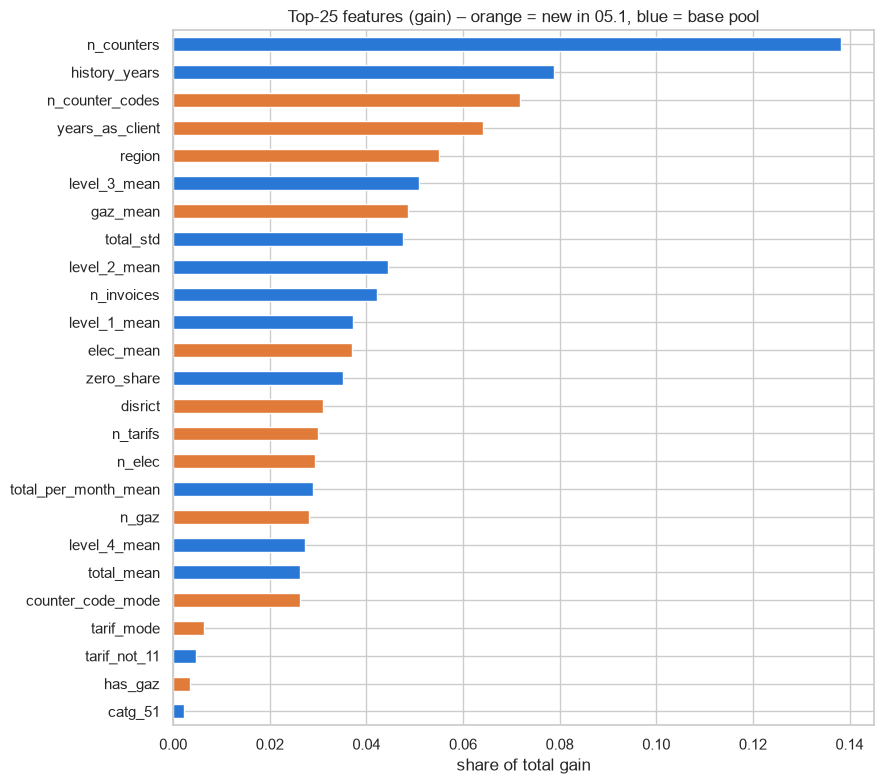

In [28]:
final_lgbm = clone(lgbm_tuned).set_params(importance_type="gain").fit(X_final, y_train)
imp = pd.Series(final_lgbm.feature_importances_, index=X_final.columns)
imp = (imp / imp.sum()).sort_values(ascending=False)

top_n = imp.head(25)[::-1]
new_cols = set(X_final.columns) - set(X_base.columns)
colors = ["#e07b39" if c in new_cols else "#2a78d6" for c in top_n.index]
top_n.plot.barh(figsize=(9, 8), color=colors)
plt.title("Top-25 features (gain) – orange = new in 05.1, blue = base pool")
plt.xlabel("share of total gain"); plt.tight_layout(); plt.show()

## 🔒 Holdout – Stage 7 only

Locked on purpose (ADR-001): run **once**, after all choices are final. Set `RUN_HOLDOUT = True` in Stage 7.

In [31]:
RUN_HOLDOUT = True

if RUN_HOLDOUT:
    holdout_invoices = clean(invoice_train[invoice_train["client_id"].isin(holdout_clients["client_id"])])
    hf = build_features(holdout_clients, holdout_invoices)
    hg = extra_features(holdout_clients, holdout_invoices)
    X_hold = make_X(FINAL_GROUPS, base=hf.drop(columns=["target", "region"]).astype(float), groups=hg)
    final_model = clone(lgbm_tuned).fit(X_final, y_train)
    p = final_model.predict_proba(X_hold[X_final.columns])[:, 1]
    print("HOLDOUT AUC:", round(roc_auc_score(hf["target"], p), 4))
else:
    print("Holdout locked – Stage 7 only.")

HOLDOUT AUC: 0.8752


# End: Results & Learnings

### Rubber-duck checklist

- [x] **Same split, CV and base features as the baseline?** → Yes.
- [x] **New features without leakage from other clients?** → Yes, all are fixed rules per client. (Leakage *in time* – end of the history – is checked in Stage 6.)
- [x] **Feature groups tested one by one, kept only above the CV spread?** → Yes (5.1.5).
- [x] **Tuning inside the CV on train only?** → Yes, `RandomizedSearchCV` with the same folds.
- [x] **Holdout untouched?** → Yes, locked cell.

### Results (*fill in after running*)

| Step | AUC (5-fold CV) |
| --- | --- |
| Logistic Regression (baseline, 17) | 0.788 |
| LightGBM, 17 features | 0.808 |
| + `region` + `disrict` | 0.829 |
| + new feature groups | 0.8665 |
| + tuning | 0.868 |
| HOLDOUT  | 0.8752 |